In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from statsmodels.stats.outliers_influence import variance_inflation_factor

In [ ]:
data = load_diabetes(as_frame=True)

df = data.frame

print(df.head())
print("Shape:", df.shape)

        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  target  
0 -0.002592  0.019907 -0.017646   151.0  
1 -0.039493 -0.068332 -0.092204    75.0  
2 -0.002592  0.002861 -0.025930   141.0  
3  0.034309  0.022688 -0.009362   206.0  
4 -0.002592 -0.031988 -0.046641   135.0  
Shape: (442, 11)


In [ ]:
X = df[['bmi', 'bp', 's5']]
y = df['target']

print(X.head())
print(y.head())

        bmi        bp        s5
0  0.061696  0.021872  0.019907
1 -0.051474 -0.026328 -0.068332
2  0.044451 -0.005670  0.002861
3 -0.011595 -0.036656  0.022688
4 -0.036385  0.021872 -0.031988
0    151.0
1     75.0
2    141.0
3    206.0
4    135.0
Name: target, dtype: float64


In [ ]:
print("Dataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Values:")
print(df.duplicated().sum())

print("\nStatistical Summary:")
print(df.describe())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB
None

Missing Values:
age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0
dtype: int64

Duplicate Values:
0

Statistical Summary:
                age           sex           bmi            bp            s1  \
count  4.420000e+02  4.420000e+02  4.420000e+02  4.420000e+02 

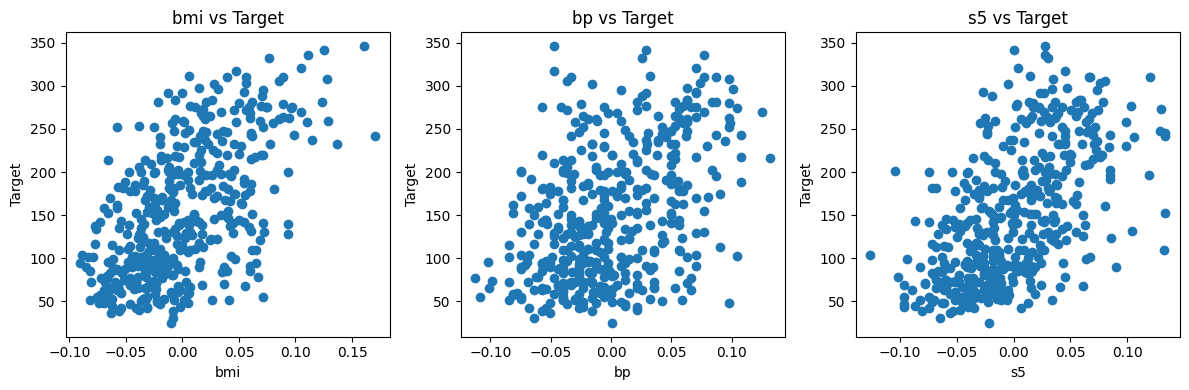

In [ ]:
plt.figure(figsize=(12,4))

for i, col in enumerate(X.columns):
    plt.subplot(1,3,i+1)
    plt.scatter(X[col], y)
    plt.xlabel(col)
    plt.ylabel('Target')
    plt.title(col + ' vs Target')

plt.tight_layout()
plt.show()

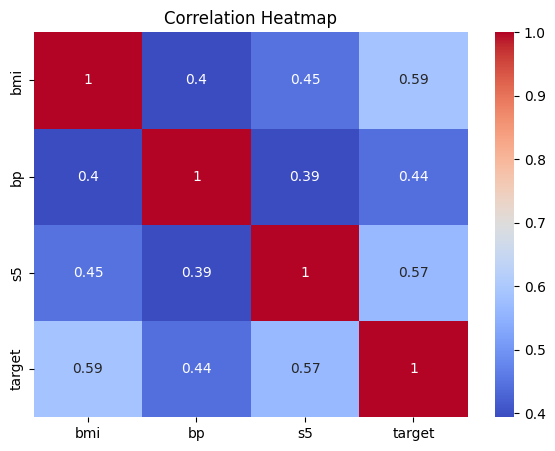

In [ ]:
plt.figure(figsize=(7,5))

sns.heatmap(df[['bmi','bp','s5','target']].corr(),
            annot=True, cmap='coolwarm')

plt.title("Correlation Heatmap")
plt.show()

In [ ]:
sample = df[['bmi','bp','target']].head(5)

print(sample)

        bmi        bp  target
0  0.061696  0.021872   151.0
1 -0.051474 -0.026328    75.0
2  0.044451 -0.005670   141.0
3 -0.011595 -0.036656   206.0
4 -0.036385  0.021872   135.0


In [ ]:
X_sample = np.column_stack((
    np.ones(len(sample)),
    sample[['bmi','bp']].values
))

y_sample = sample['target'].values

print("Design Matrix X:")
print(X_sample)

print("Target Vector Y:")
print(y_sample)

Design Matrix X:
[[ 1.          0.06169621  0.02187239]
 [ 1.         -0.05147406 -0.02632753]
 [ 1.          0.04445121 -0.00567042]
 [ 1.         -0.01159501 -0.03665608]
 [ 1.         -0.03638469  0.02187239]]
Target Vector Y:
[151.  75. 141. 206. 135.]


In [ ]:
XT_X = X_sample.T @ X_sample
XT_Y = X_sample.T @ y_sample

print("X Transpose X:")
print(XT_X)

print("X Transpose Y:")
print(XT_Y)

X Transpose X:
[[ 5.00000000e+00  6.69365191e-03 -2.49092605e-02]
 [ 6.69365191e-03  9.89020143e-03  2.08177864e-03]
 [-2.49092605e-02  2.08177864e-03  3.02576320e-03]]
X Transpose Y:
[708.           4.42268724  -4.0697446 ]


In [ ]:
b = np.linalg.solve(XT_X, XT_Y)

print("b0 =", b[0])
print("b1 =", b[1])
print("b2 =", b[2])

b0 = 138.36174480441028
b1 = 464.10486370620026
b2 = -525.2953847580584


In [ ]:
manual_model = LinearRegression()

manual_model.fit(sample[['bmi','bp']], sample['target'])

print("Intercept:", manual_model.intercept_)
print("Coefficients:", manual_model.coef_)

Intercept: 138.36174480441025
Coefficients: [ 464.10486371 -525.29538476]


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (353, 3)
Testing Data: (89, 3)


In [ ]:
single_feature = ['bmi']

single_model = LinearRegression()

single_model.fit(X_train[single_feature], y_train)

single_pred = single_model.predict(X_test[single_feature])

print("Intercept:", single_model.intercept_)
print("Coefficient:", single_model.coef_)
print("R2 Score:", r2_score(y_test, single_pred))

Intercept: 152.00335421448167
Coefficient: [998.57768914]
R2 Score: 0.23335039815872138


In [ ]:
multi_model = LinearRegression()

multi_model.fit(X_train, y_train)

multi_pred = multi_model.predict(X_test)

print("Intercept:", multi_model.intercept_)

print("Coefficients:")
for name, value in zip(X.columns, multi_model.coef_):
    print(name, ":", value)

Intercept: 151.67416300012866
Coefficients:
bmi : 650.6313834139721
bp : 283.8989003965992
s5 : 491.9827115876336


In [ ]:
def evaluate_model(y_true, y_pred, p):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)

    n = len(y_true)
    adj_r2 = 1 - ((1-r2)*(n-1)/(n-p-1))

    return [mae, mse, rmse, r2, adj_r2]

single_results = evaluate_model(y_test, single_pred, 1)

multi_results = evaluate_model(y_test, multi_pred, 3)

results = pd.DataFrame(
    [single_results, multi_results],
    columns=['MAE','MSE','RMSE','R2','Adjusted R2'],
    index=['Single Regression','Multiple Regression']
)

print(results)

                           MAE          MSE       RMSE        R2  Adjusted R2
Single Regression    52.259976  4061.825928  63.732456  0.233350     0.224538
Multiple Regression  44.288196  2891.037211  53.768366  0.454331     0.435072


In [ ]:
comparison = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': multi_pred
})

print(comparison.head(10))

   Actual   Predicted
0   219.0  159.050426
1    70.0  170.818512
2   202.0  187.042594
3   230.0  256.540631
4   111.0  135.357742
5    84.0  117.714504
6   242.0  283.454544
7   272.0  224.006962
8    94.0   88.501758
9    96.0  141.014585


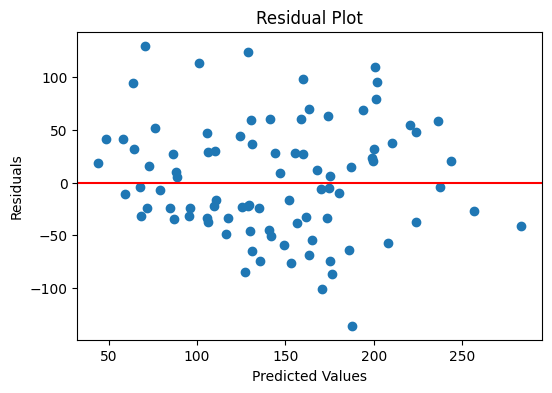

In [ ]:
residuals = y_test - multi_pred

plt.figure(figsize=(6,4))
plt.scatter(multi_pred, residuals)
plt.axhline(0, color='red')
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()

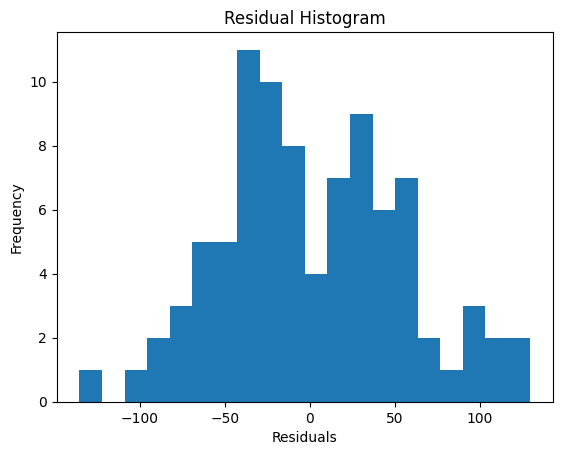

In [ ]:
plt.hist(residuals, bins=20)
plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.title("Residual Histogram")
plt.show()

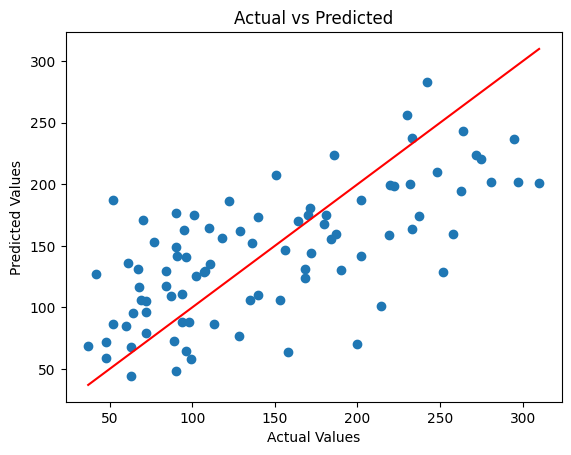

In [ ]:
plt.scatter(y_test, multi_pred)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red'
)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted")
plt.show()

In [ ]:
vif = pd.DataFrame()

vif['Feature'] = X.columns

vif['VIF'] = [
    variance_inflation_factor(X.values, i)
    for i in range(X.shape[1])
]

print(vif)

  Feature       VIF
0     bmi  1.344534
1      bp  1.274172
2      s5  1.342110


In [ ]:
new_data = pd.DataFrame({
    'bmi': [X_train['bmi'].median()],
    'bp': [X_train['bp'].median()],
    's5': [X_train['s5'].median()]
})

new_prediction = multi_model.predict(new_data)

print("New Predicted Value:", new_prediction[0])

New Predicted Value: 146.42684298842337
